# Adam and a Realistic Experiment

In the previous chapters, we built a Neural Network from scratch, we computed its gradient with backpropagation, and we trained it with Gradient Descent and Stochastic Gradient Descent. We also observed that SGD has a few weak points:

- it is very **sensitive to the learning rate**, which has to be tuned by hand;
- it uses **the same learning rate for all the parameters**, even if the loss may have very different curvatures along different directions (**ill-conditioning**);
- its updates are **noisy**, which makes the iterates bounce around the minimum.

In this last chapter, we introduce **Adam** (*Adaptive Moment Estimation*, Kingma and Ba, 2014), which is, by far, the most used optimizer in modern Deep Learning. We will build it step by step, starting from two simpler ideas: **momentum** and **adaptive learning rates**. Then, we will put everything together in a realistic experiment: we will download a real image classification dataset, and we will train an MLP on it, from scratch, comparing SGD and Adam.

## Momentum

Let's go back to the ill-conditioned quadratic function of the GD chapter, $f(x) = \frac{1}{2}(x_1^2 + \lambda x_2^2)$. We observed that GD **zig-zags** across the narrow valley: the gradient keeps changing sign along the steep direction $x_2$, while it is small and always with the same sign along the flat direction $x_1$.

The idea of **momentum** (also known as *heavy-ball* method, Polyak, 1964) is to think of the iterate as a **ball rolling down the graph of $f$**: the ball does not only follow the slope at its current position, but it also keeps memory of its previous velocity. Mathematically, we introduce a *velocity* vector $m^{(k)}$, which accumulates the past gradients:

$$
\begin{aligned}
m^{(k)} &= \beta \, m^{(k-1)} + g^{(k)}, \\
\Theta^{(k+1)} &= \Theta^{(k)} - \eta \, m^{(k)},
\end{aligned}
$$

where $g^{(k)} = \nabla_\Theta \mathcal{L}(\Theta^{(k)}; \mathcal{M}_k)$ is the (stochastic) gradient, $m^{(-1)} = 0$, and $\beta \in [0, 1)$ is the **momentum** parameter (typically $\beta = 0.9$). For $\beta = 0$, we recover SGD. Unrolling the recursion, we get

$$
m^{(k)} = \sum_{j=0}^{k} \beta^{k-j} g^{(j)},
$$

i.e. the update direction is a weighted sum of all the past gradients, where older gradients have exponentially smaller weights. As a consequence:

- along directions where the gradient **keeps the same sign** (the flat direction $x_1$), the contributions accumulate, and the iterate **accelerates** (up to a factor $\frac{1}{1-\beta} = 10$ for $\beta = 0.9$);
- along directions where the gradient **oscillates** (the steep direction $x_2$), the contributions cancel out, and the oscillations are **damped**;
- in the stochastic setting, averaging over many past gradients also **reduces the noise** of the stochastic gradient.

## Adaptive learning rates: RMSProp

Momentum mitigates ill-conditioning, but it still uses the same learning rate $\eta$ for all the parameters. However, in a Neural Network, different parameters may have gradients with very different magnitudes (for example, the weights of the first layer versus the weights of the last layer). A learning rate that is good for some parameters may be too large or too small for others.

The idea of **adaptive** methods is to use a **different learning rate for each parameter**, which is automatically adjusted based on the magnitude of its past gradients. The most popular adaptive method before Adam is **RMSProp** (Hinton, 2012), which keeps track of an exponential moving average of the **squared** gradients:

$$
\begin{aligned}
v^{(k)} &= \beta_2 \, v^{(k-1)} + (1 - \beta_2) \, (g^{(k)})^2, \\
\Theta^{(k+1)} &= \Theta^{(k)} - \eta \, \frac{g^{(k)}}{\sqrt{v^{(k)}} + \varepsilon},
\end{aligned}
$$

where all the operations (square, square root and division) are applied **element-wise**, and $\varepsilon \approx 10^{-8}$ is a small constant avoiding divisions by zero. The quantity $\sqrt{v^{(k)}_j}$ is an estimate of the typical magnitude (the *Root Mean Square*, from which the name) of the $j$-th component of the gradient. Therefore, each component of the gradient is **normalized** by its own typical magnitude: parameters with large gradients take smaller steps, and parameters with small gradients take larger steps. In the ill-conditioned quadratic example, this means that the steep direction and the flat direction are treated in the same way.

## Adam: Adaptive Moment Estimation

**Adam** combines the two ideas above: it uses **momentum** to smooth the gradient direction, and **adaptive learning rates** to rescale each component. Given the stochastic gradient $g^{(k)}$, Adam maintains two **exponential moving averages (EMAs)**:

$$
\begin{aligned}
m^{(k)} &= \beta_1\, m^{(k-1)} + (1-\beta_1)\, g^{(k)} &&\text{(first moment: mean of the gradients)}, \\
v^{(k)} &= \beta_2\, v^{(k-1)} + (1-\beta_2)\, (g^{(k)})^2 &&\text{(second moment: uncentered variance of the gradients)},
\end{aligned}
$$

with $m^{(-1)} = v^{(-1)} = 0$.

### Bias correction

Since $m$ and $v$ are initialized to zero, they are **biased toward zero** in the first iterations. Indeed, unrolling the recursion and assuming, for simplicity, that the gradients $g^{(j)}$ are identically distributed with mean $\mathbb{E}[g]$, we have

$$
\mathbb{E}[m^{(k)}] = (1 - \beta_1) \sum_{j=0}^{k} \beta_1^{k-j} \, \mathbb{E}[g] = (1 - \beta_1^{k+1}) \, \mathbb{E}[g],
$$

where we used the formula for the geometric sum. For example, at the first iteration ($k = 0$) with $\beta_1 = 0.9$, $m^{(0)} = 0.1 \, g^{(0)}$, which is $10$ times smaller than the gradient. The same holds for $v^{(k)}$, with $\beta_2$ in place of $\beta_1$. To remove this bias, Adam divides the moments by the factors $(1 - \beta_1^{k+1})$ and $(1 - \beta_2^{k+1})$:

$$
\hat m^{(k)} = \frac{m^{(k)}}{1-\beta_1^{k+1}},
\qquad
\hat v^{(k)} = \frac{v^{(k)}}{1-\beta_2^{k+1}}.
$$

Note that, as $k$ grows, the correction factors go to $1$, and the bias correction becomes irrelevant.

### The algorithm

Putting everything together, the **Adam** algorithm reads:

**Input**: initial parameters $\Theta^{(0)}$, learning rate $\eta$, $\beta_1, \beta_2 \in [0, 1)$, $\varepsilon > 0$, batch size $N_\text{batch}$, number of epochs $E$.
Initialize $m^{(-1)} = v^{(-1)} = 0$ and $k = 0$.
**For** each epoch, shuffle and split the dataset into batches and, **for** each batch $\mathcal{M}_k$:
1. Compute the stochastic gradient: $g^{(k)} = \nabla_\Theta \mathcal{L}(\Theta^{(k)}; \mathcal{M}_k)$.
2. Update the moments:

   $$
   m^{(k)} = \beta_1\, m^{(k-1)} + (1-\beta_1)\, g^{(k)}, \qquad v^{(k)} = \beta_2\, v^{(k-1)} + (1-\beta_2)\, (g^{(k)})^2.
   $$
3. Correct the bias:

   $$
   \hat m^{(k)} = \frac{m^{(k)}}{1-\beta_1^{k+1}}, \qquad \hat v^{(k)} = \frac{v^{(k)}}{1-\beta_2^{k+1}}.
   $$
4. Update the parameters:

   $$
   \Theta^{(k+1)} = \Theta^{(k)} - \eta\, \frac{\hat m^{(k)}}{\sqrt{\hat v^{(k)}} + \varepsilon}.
   $$
5. $k \leftarrow k + 1$.

The default values, suggested in the original paper and used almost everywhere, are $\eta = 10^{-3}$, $\beta_1=0.9$, $\beta_2=0.999$, $\varepsilon = 10^{-8}$.

```{note}
Since each component of $\hat m^{(k)}$ is divided by (an estimate of) its typical magnitude $\sqrt{\hat v^{(k)}}$, the size of the update of each parameter is roughly bounded by the learning rate $\eta$, **independently of the scale of the gradient**. For example, if we multiply the loss function by a constant $c > 0$, the iterates of SGD change (the effective learning rate becomes $c \, \eta$), while the iterates of Adam remain (almost) the same. This is the main reason why Adam is much **less sensitive to the choice of the learning rate** than SGD, and why its default learning rate $\eta = 10^{-3}$ works well in a wide range of problems.
```

```{note}
In modern Deep Learning (e.g. for training Large Language Models), the most used optimizer is **AdamW**, a variant of Adam which also includes a *weight decay* term, $\Theta^{(k+1)} = \Theta^{(k)} - \eta \left( \frac{\hat m^{(k)}}{\sqrt{\hat v^{(k)}} + \varepsilon} + \lambda \Theta^{(k)} \right)$, which keeps the weights small and improves generalization.
```

### A first comparison on the ill-conditioned quadratic

Before moving to Neural Networks, let's visualize the behavior of GD, GD with Momentum and Adam on the ill-conditioned quadratic function $f(x) = \frac{1}{2}(x_1^2 + \lambda x_2^2)$, with $\lambda = 25$. Since here the gradient is exact, there is no stochasticity: we only observe the effect of momentum and of the adaptive learning rates.

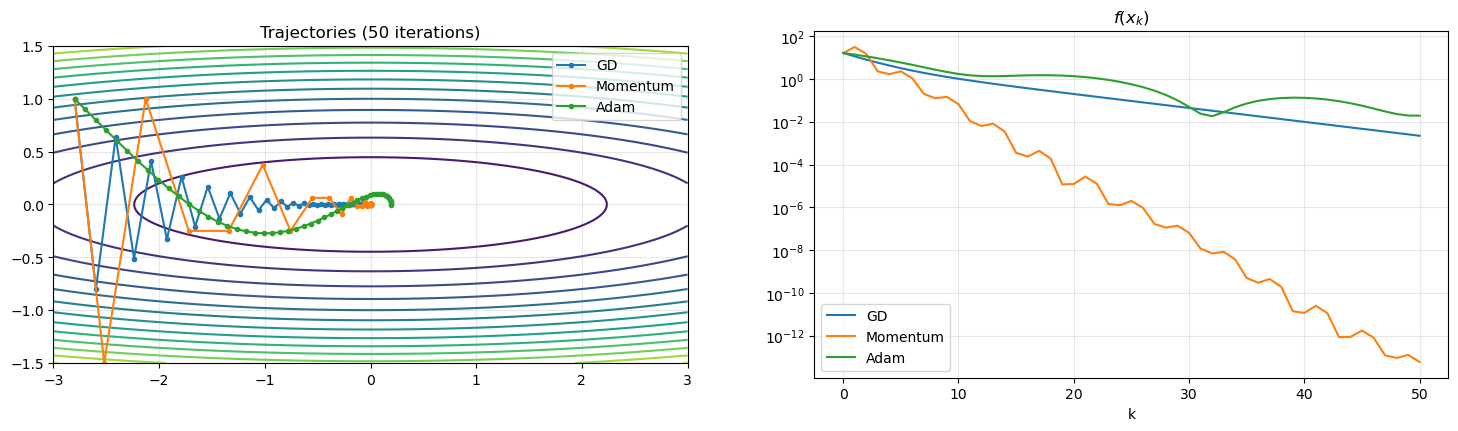

In [1]:
import numpy as np
import matplotlib.pyplot as plt

lam = 25
f = lambda x: 0.5 * (x[0]**2 + lam * x[1]**2)
grad_f = lambda x: np.array([x[0], lam * x[1]])

def run_gd(x0, eta, maxit):
    x = x0.copy(); xs = [x.copy()]
    for k in range(maxit):
        x = x - eta * grad_f(x)
        xs.append(x.copy())
    return np.array(xs)

def run_momentum(x0, eta, beta, maxit):
    x = x0.copy(); m = np.zeros_like(x); xs = [x.copy()]
    for k in range(maxit):
        m = beta * m + grad_f(x)
        x = x - eta * m
        xs.append(x.copy())
    return np.array(xs)

def run_adam(x0, eta, maxit, beta1=0.9, beta2=0.999, eps=1e-8):
    x = x0.copy(); m = np.zeros_like(x); v = np.zeros_like(x); xs = [x.copy()]
    for k in range(maxit):
        g = grad_f(x)
        m = beta1 * m + (1 - beta1) * g
        v = beta2 * v + (1 - beta2) * g**2
        m_hat = m / (1 - beta1**(k + 1))
        v_hat = v / (1 - beta2**(k + 1))
        x = x - eta * m_hat / (np.sqrt(v_hat) + eps)
        xs.append(x.copy())
    return np.array(xs)

x0 = np.array([-2.8, 1.0])
maxit = 50
trajectories = {
    "GD": run_gd(x0, eta=1.8 / lam, maxit=maxit),
    "Momentum": run_momentum(x0, eta=2.5 / lam, beta=0.5, maxit=maxit),
    "Adam": run_adam(x0, eta=0.1, maxit=maxit),
}

xx1, xx2 = np.meshgrid(np.linspace(-3, 3, 300), np.linspace(-1.5, 1.5, 300))
fig, axes = plt.subplots(1, 2, figsize=(18, 4.5))
axes[0].contour(xx1, xx2, 0.5 * (xx1**2 + lam * xx2**2), levels=15, cmap="viridis")
for name, xs in trajectories.items():
    axes[0].plot(xs[:, 0], xs[:, 1], 'o-', ms=3, label=name)
    axes[1].semilogy([f(x) for x in xs], label=name)
axes[0].set_aspect("equal")
axes[0].set_title(f"Trajectories ({maxit} iterations)")
axes[1].set_title("$f(x_k)$")
axes[1].set_xlabel("k")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)
plt.show()

GD zig-zags along the valley and moves slowly in the flat direction. Momentum damps the oscillations and accelerates along the flat direction, converging much faster than GD. Adam, thanks to the per-coordinate normalization, does not zig-zag at all: at the beginning, it moves roughly along the diagonal, treating the two directions in the same way, regardless of their curvature. 

Note, however, that on this (deterministic, perfectly known) problem, Adam is **not** the fastest method: with a constant learning rate, it does not converge exactly to the minimum, but it keeps oscillating in a small neighborhood of it, whose size is proportional to $\eta$. Its real advantage is a different one: the learning rates of GD and Momentum must be chosen proportional to $1/\lambda = 1/L$ (try to increase them, and they diverge!), while the learning rate of Adam is **independent of the curvature** of the function. As we will see, this robustness is what makes Adam so useful for training Neural Networks, where $L$ is unknown.

## A realistic experiment: Fashion-MNIST

We are now ready to put everything together. We will:

1. **download** a real classification dataset from the internet;
2. **load** it in memory as `numpy` arrays;
3. **pre-process** it (normalization, one-hot encoding, train/validation/test split);
4. **build** an MLP from scratch;
5. **train** it with SGD, SGD with Momentum and Adam, implemented from scratch;
6. **evaluate** the trained model on the test set.

### The dataset

We will use **Fashion-MNIST** (Xiao, Rasul and Vollgraf, 2017), a dataset of $70\,000$ grayscale images of $28 \times 28$ pixels, each representing a clothing item from the Zalando catalog, belonging to one of $K = 10$ classes:

| Label | Class | Label | Class |
|---|---|---|---|
| 0 | T-shirt/top | 5 | Sandal |
| 1 | Trouser | 6 | Shirt |
| 2 | Pullover | 7 | Sneaker |
| 3 | Dress | 8 | Bag |
| 4 | Coat | 9 | Ankle boot |

The dataset is split into $60\,000$ training images and $10\,000$ test images. It has been designed as a drop-in replacement of the classical MNIST dataset of handwritten digits (same size, same format, same number of classes), but it is significantly harder to classify. The dataset is publicly available on [GitHub](https://github.com/zalandoresearch/fashion-mnist).

### Downloading the data

The dataset is distributed as four compressed (`.gz`) files: images and labels, for the training and the test set. We download them with the `urllib` module of the Python standard library, saving them in the `data/fashion_mnist` folder (if they have not been already downloaded).

In [2]:
import os
import gzip
import urllib.request

URL = "https://github.com/zalandoresearch/fashion-mnist/raw/master/data/fashion/"
FILES = {
    "X_train": "train-images-idx3-ubyte.gz",
    "y_train": "train-labels-idx1-ubyte.gz",
    "X_test": "t10k-images-idx3-ubyte.gz",
    "y_test": "t10k-labels-idx1-ubyte.gz",
}
DATA_DIR = "data/fashion_mnist"

os.makedirs(DATA_DIR, exist_ok=True)
for name, filename in FILES.items():
    path = os.path.join(DATA_DIR, filename)
    if not os.path.exists(path):
        print(f"Downloading {filename}...")
        urllib.request.urlretrieve(URL + filename, path)
    print(f"{filename}: {os.path.getsize(path) / 1e6:.1f} MB")

train-images-idx3-ubyte.gz: 26.4 MB
train-labels-idx1-ubyte.gz: 0.0 MB
t10k-images-idx3-ubyte.gz: 4.4 MB
t10k-labels-idx1-ubyte.gz: 0.0 MB


### Loading the data in memory

The files are stored in the **IDX** format, a very simple binary format for vectors and multidimensional arrays: each file starts with a short *header* (a "magic number" identifying the type of data, followed by the size of each dimension, each of them stored as a 4-byte integer), followed by the raw data, stored as unsigned 8-bit integers (`uint8`, i.e. numbers in $\{0, \dots, 255\}$). In particular:

- the **images** files have a header of $16$ bytes (magic number, number of images, number of rows, number of columns), followed by the pixel values;
- the **labels** files have a header of $8$ bytes (magic number, number of labels), followed by the labels.

Therefore, we can read them with `numpy`, by skipping the header with the `offset` argument of `np.frombuffer`.

In [3]:
def load_images(path):
    with gzip.open(path, "rb") as f:
        data = np.frombuffer(f.read(), dtype=np.uint8, offset=16)
    return data.reshape(-1, 28, 28)

def load_labels(path):
    with gzip.open(path, "rb") as f:
        data = np.frombuffer(f.read(), dtype=np.uint8, offset=8)
    return data.astype(int)

X_train_full = load_images(os.path.join(DATA_DIR, FILES["X_train"]))
y_train_full = load_labels(os.path.join(DATA_DIR, FILES["y_train"]))
X_test = load_images(os.path.join(DATA_DIR, FILES["X_test"]))
y_test = load_labels(os.path.join(DATA_DIR, FILES["y_test"]))

print(f"Training images: {X_train_full.shape}, dtype: {X_train_full.dtype}")
print(f"Training labels: {y_train_full.shape}, values: {np.unique(y_train_full)}")
print(f"Test images: {X_test.shape}")
print(f"Number of training images per class: {np.bincount(y_train_full)}")

Training images: (60000, 28, 28), dtype: uint8
Training labels: (60000,), values: [0 1 2 3 4 5 6 7 8 9]
Test images: (10000, 28, 28)
Number of training images per class: [6000 6000 6000 6000 6000 6000 6000 6000 6000 6000]


The training set is perfectly **balanced**: each class contains $6\,000$ images. Let's visualize some of them.

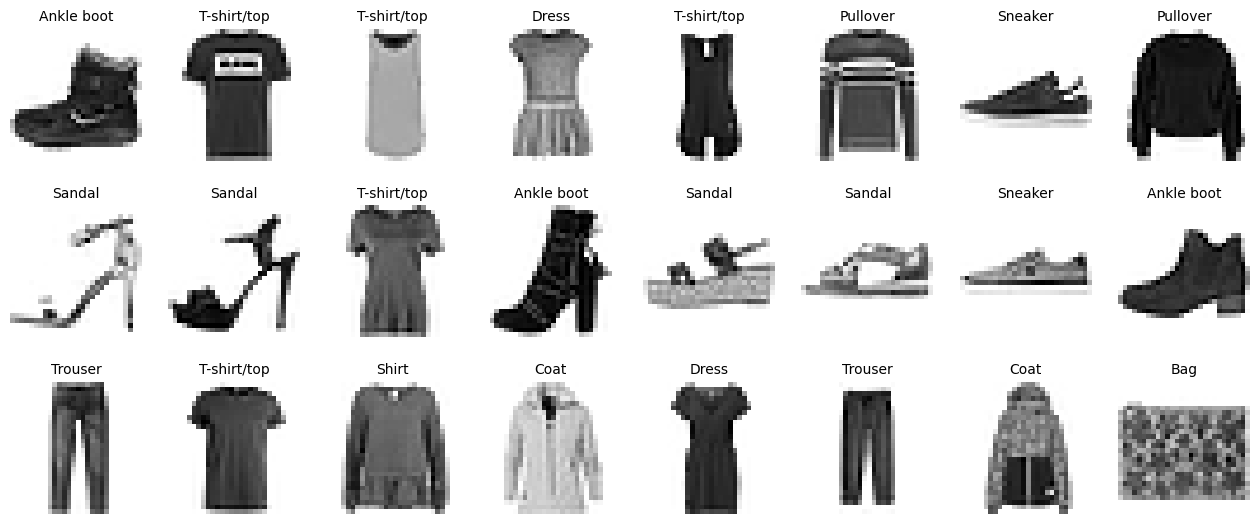

In [4]:
CLASSES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
           "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

fig, axes = plt.subplots(3, 8, figsize=(16, 6.5))
for ax, i in zip(axes.ravel(), range(24)):
    ax.imshow(X_train_full[i], cmap="gray_r")
    ax.set_title(CLASSES[y_train_full[i]], fontsize=10)
    ax.axis("off")
plt.show()

### Pre-processing

Before training, we need to transform the data in the format required by our MLP:

1. **Flattening**: our MLP takes as input vectors, not matrices. Therefore, each $28 \times 28$ image is *flattened* into a vector $x \in \mathbb{R}^{784}$ (by concatenating its rows), so that the dataset becomes a matrix $X \in \mathbb{R}^{N \times 784}$.
2. **Normalization**: the pixel values are integers in $\{0, \dots, 255\}$. As we discussed in the previous chapters, large and unbalanced input values lead to an ill-conditioned optimization problem. Therefore, we first rescale the pixels to $[0, 1]$, and then we **standardize** them to have zero mean and unit variance:

   $$
   x \leftarrow \frac{x - \mu}{\sigma},
   $$

   where $\mu$ and $\sigma$ are the mean and the standard deviation of the pixels in the **training set**.
3. **Train/validation split**: we keep the last $10\,000$ images of the training set aside, as a **validation set**, which we use to monitor the training and to compare the optimizers. The **test set** is used only once, at the very end.
4. **One-hot encoding** of the labels.

```{warning}
The normalization constants $\mu$ and $\sigma$ must be computed **only on the training set**, and then applied, unchanged, to the validation and test sets. Using the test set to compute them would be a (small) form of *data leakage*, i.e. we would use information about the test set during training.
```

In [5]:
# 1. Flattening and conversion to float in [0, 1]
X_train_full = X_train_full.reshape(-1, 784).astype(np.float64) / 255.0
X_test = X_test.reshape(-1, 784).astype(np.float64) / 255.0

# 3. Train / validation split
N_val = 10000
X_train, y_train = X_train_full[:-N_val], y_train_full[:-N_val]
X_val, y_val = X_train_full[-N_val:], y_train_full[-N_val:]

# 2. Standardization (statistics computed on the training set only!)
mu, sigma = X_train.mean(), X_train.std()
X_train = (X_train - mu) / sigma
X_val = (X_val - mu) / sigma
X_test = (X_test - mu) / sigma

# 4. One-hot encoding
K = 10
Y_train = np.eye(K)[y_train]
Y_val = np.eye(K)[y_val]
Y_test = np.eye(K)[y_test]

print(f"Train: X {X_train.shape}, Y {Y_train.shape}")
print(f"Validation: X {X_val.shape}, Y {Y_val.shape}")
print(f"Test: X {X_test.shape}, Y {Y_test.shape}")

Train: X (50000, 784), Y (50000, 10)
Validation: X (10000, 784), Y (10000, 10)
Test: X (10000, 784), Y (10000, 10)


### The model

We use an MLP with two hidden layers of $256$ and $128$ neurons, with ReLU activation, and a Softmax output layer with $K = 10$ neurons:

$$
\mathbb{R}^{784} \xrightarrow{W^1, b^1} \mathbb{R}^{256} \xrightarrow{\text{ReLU}} \mathbb{R}^{256} \xrightarrow{W^2, b^2} \mathbb{R}^{128} \xrightarrow{\text{ReLU}} \mathbb{R}^{128} \xrightarrow{W^3, b^3} \mathbb{R}^{10} \xrightarrow{\text{softmax}} \hat{y}.
$$

The code for the MLP is the same as in the previous chapters (expand the cell below to see it).

In [6]:
import time

# ---- Code from the previous chapters ----
def relu(z):
    return np.maximum(0, z)

def relu_prime(z):
    return (z > 0).astype(float)

def softmax(z):
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

def init_params(sizes, seed=0):
    rng = np.random.default_rng(seed)
    params = []
    for n_in, n_out in zip(sizes[:-1], sizes[1:]):
        W = rng.normal(0, np.sqrt(2 / n_in), (n_out, n_in))
        b = np.zeros(n_out)
        params.append([W, b])
    return params

def forward(params, X):
    H = X
    cache = [(None, X)]
    for l, (W, b) in enumerate(params):
        Z = H @ W.T + b
        H = softmax(Z) if l == len(params) - 1 else relu(Z)
        cache.append((Z, H))
    return H, cache

def cross_entropy(Y_hat, Y):
    return -np.mean(np.sum(Y * np.log(Y_hat + 1e-12), axis=1))

def backward(params, cache, Y):
    N = Y.shape[0]
    grads = [None] * len(params)
    Delta = (cache[-1][1] - Y) / N
    for l in reversed(range(len(params))):
        W, b = params[l]
        H_prev = cache[l][1]
        grads[l] = [Delta.T @ H_prev, Delta.sum(axis=0)]
        if l > 0:
            Delta = (Delta @ W) * relu_prime(cache[l][0])
    return grads

def accuracy(Y_hat, y):
    return np.mean(Y_hat.argmax(axis=1) == y)

In [7]:
sizes = [784, 256, 128, 10]
params = init_params(sizes)
n_params = sum(W.size + b.size for W, b in params)
print(f"Number of parameters: {n_params}")

Number of parameters: 235146


### The optimizers

To compare different optimizers with the same training loop, we implement each optimizer as a small Python **class**, with a method `step(params, grads)` which updates the parameters in-place, given their gradients. Each optimizer stores its own internal state (e.g. the moments $m$ and $v$ for Adam), with one array for each parameter array. This is exactly the structure used by the optimizers of PyTorch (`torch.optim.SGD`, `torch.optim.Adam`, ...).

In [8]:
class SGD:
    def __init__(self, params, lr=1e-2):
        self.lr = lr

    def step(self, params, grads):
        for (W, b), (dW, db) in zip(params, grads):
            W -= self.lr * dW
            b -= self.lr * db


class Momentum:
    def __init__(self, params, lr=1e-2, beta=0.9):
        self.lr, self.beta = lr, beta
        self.m = [[np.zeros_like(W), np.zeros_like(b)] for W, b in params]

    def step(self, params, grads):
        for layer, grad_layer, m_layer in zip(params, grads, self.m):
            for j in range(2):  # j = 0: W, j = 1: b
                m_layer[j] = self.beta * m_layer[j] + grad_layer[j]
                layer[j] -= self.lr * m_layer[j]


class Adam:
    def __init__(self, params, lr=1e-3, beta1=0.9, beta2=0.999, eps=1e-8):
        self.lr, self.beta1, self.beta2, self.eps = lr, beta1, beta2, eps
        self.m = [[np.zeros_like(W), np.zeros_like(b)] for W, b in params]
        self.v = [[np.zeros_like(W), np.zeros_like(b)] for W, b in params]
        self.k = 0

    def step(self, params, grads):
        self.k += 1
        for layer, grad_layer, m_layer, v_layer in zip(params, grads, self.m, self.v):
            for j in range(2):  # j = 0: W, j = 1: b
                g = grad_layer[j]
                m_layer[j] = self.beta1 * m_layer[j] + (1 - self.beta1) * g
                v_layer[j] = self.beta2 * v_layer[j] + (1 - self.beta2) * g**2
                m_hat = m_layer[j] / (1 - self.beta1**self.k)
                v_hat = v_layer[j] / (1 - self.beta2**self.k)
                layer[j] -= self.lr * m_hat / (np.sqrt(v_hat) + self.eps)

### The training loop

The training loop is the same as in the previous chapter, with two differences: the update of the parameters is delegated to the optimizer, and at the end of each epoch we evaluate the model on the **validation set**. To save time, the training loss of each epoch is computed as the average of the losses on the batches (which are computed anyway during the forward pass), instead of performing an additional forward pass on the whole training set.

In [9]:
def train(params, optimizer, X_train, Y_train, X_val, Y_val, batch_size=64, epochs=10, seed=0, verbose=True):
    rng = np.random.default_rng(seed)
    N = X_train.shape[0]
    history = {"train_loss": [], "val_loss": [], "val_acc": []}

    for epoch in range(epochs):
        start = time.time()
        idx = rng.permutation(N)
        batch_losses = []

        for start_batch in range(0, N, batch_size):
            batch_idx = idx[start_batch:start_batch + batch_size]
            Xb, Yb = X_train[batch_idx], Y_train[batch_idx]

            # Forward pass, backward pass, update
            Y_hat, cache = forward(params, Xb)
            grads = backward(params, cache, Yb)
            optimizer.step(params, grads)

            batch_losses.append(cross_entropy(Y_hat, Yb))

        # Evaluation on the validation set
        Y_hat_val, _ = forward(params, X_val)
        history["train_loss"].append(np.mean(batch_losses))
        history["val_loss"].append(cross_entropy(Y_hat_val, Y_val))
        history["val_acc"].append(accuracy(Y_hat_val, Y_val.argmax(axis=1)))

        if verbose:
            print(f"Epoch {epoch + 1:2d}/{epochs}: train loss = {history['train_loss'][-1]:.4f}, "
                  f"val loss = {history['val_loss'][-1]:.4f}, val acc = {history['val_acc'][-1]*100:.2f}% "
                  f"({time.time() - start:.1f}s)")
    return params, history

### Training

We now train the same network (with the same initialization) with the three optimizers, for $10$ epochs, with batch size $N_\text{batch} = 64$. For Adam, we use the default hyperparameters. For SGD and Momentum, we use learning rates that have been tuned by trial and error (note that, since the momentum accumulates the gradients, its effective learning rate is $\frac{\eta}{1 - \beta} = 10\,\eta$).

In [10]:
epochs = 10
batch_size = 64
optimizers = {
    "SGD": lambda p: SGD(p, lr=0.05),
    "Momentum": lambda p: Momentum(p, lr=0.005, beta=0.9),
    "Adam": lambda p: Adam(p, lr=1e-3),
}

histories, trained_params = {}, {}
for name, make_optimizer in optimizers.items():
    print(f"---- {name} ----")
    params = init_params(sizes, seed=0)
    params, history = train(params, make_optimizer(params), X_train, Y_train, X_val, Y_val,
                            batch_size=batch_size, epochs=epochs)
    histories[name], trained_params[name] = history, params

---- SGD ----
Epoch  1/10: train loss = 0.5028, val loss = 0.4978, val acc = 81.56% (1.2s)
Epoch  2/10: train loss = 0.3656, val loss = 0.3792, val acc = 86.43% (1.2s)
Epoch  3/10: train loss = 0.3261, val loss = 0.4769, val acc = 82.24% (1.1s)
Epoch  4/10: train loss = 0.2989, val loss = 0.4070, val acc = 85.44% (1.2s)
Epoch  5/10: train loss = 0.2762, val loss = 0.3407, val acc = 87.47% (1.1s)
Epoch  6/10: train loss = 0.2594, val loss = 0.4008, val acc = 85.47% (1.1s)
Epoch  7/10: train loss = 0.2436, val loss = 0.3486, val acc = 87.36% (1.1s)
Epoch  8/10: train loss = 0.2289, val loss = 0.3148, val acc = 88.77% (1.1s)
Epoch  9/10: train loss = 0.2151, val loss = 0.3410, val acc = 87.43% (1.1s)
Epoch 10/10: train loss = 0.2041, val loss = 0.3366, val acc = 88.15% (1.2s)
---- Momentum ----
Epoch  1/10: train loss = 0.4999, val loss = 0.4232, val acc = 84.35% (1.3s)
Epoch  2/10: train loss = 0.3671, val loss = 0.3877, val acc = 85.55% (1.4s)
Epoch  3/10: train loss = 0.3255, val loss 

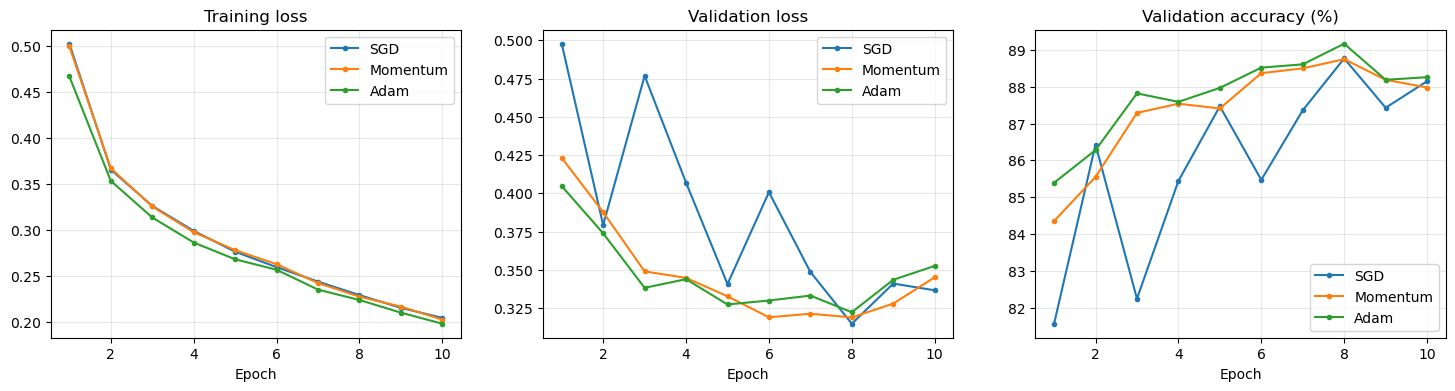

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for name, history in histories.items():
    ep = np.arange(1, epochs + 1)
    axes[0].plot(ep, history["train_loss"], 'o-', ms=3, label=name)
    axes[1].plot(ep, history["val_loss"], 'o-', ms=3, label=name)
    axes[2].plot(ep, np.array(history["val_acc"]) * 100, 'o-', ms=3, label=name)
axes[0].set_title("Training loss")
axes[1].set_title("Validation loss")
axes[2].set_title("Validation accuracy (%)")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.3)
    ax.legend()
plt.show()

A few observations:

- All the optimizers reach a validation accuracy of almost $90\%$ in a few epochs. Since the data has been standardized and the learning rates of SGD and Momentum have been tuned, the difference between them in terms of training loss is small (Adam is slightly faster, especially in the first epoch).
- The validation curves of SGD are much **noisier** than the ones of Momentum and Adam: averaging the gradients over the iterations reduces the noise of the stochastic gradient, and makes the training more stable.
- After a few epochs, the **validation loss** stops decreasing (and even starts increasing), while the training loss keeps decreasing: the model starts to **overfit** the training data. This is the moment to stop the training (*early stopping*).
- Note that an epoch of Adam takes longer than an epoch of SGD, since Adam performs more operations per iteration. In our implementation, this overhead is significant since our network is small; for large networks, the cost of the forward and backward passes dominates, and the overhead becomes negligible.

### Sensitivity to the learning rate

The comparison above is somehow unfair toward Adam: we tuned the learning rate of SGD, while we used the default learning rate for Adam. In practice, tuning the learning rate is expensive, since it requires training the model many times. Let's see what happens to SGD and Adam when the learning rate changes over several orders of magnitude (for time reasons, we only train for $2$ epochs).

In [12]:
learning_rates = [1e-4, 1e-3, 1e-2, 1e-1, 1]
sensitivity = {"SGD": [], "Adam": []}

for lr in learning_rates:
    for name, Opt in [("SGD", SGD), ("Adam", Adam)]:
        params = init_params(sizes, seed=0)
        with np.errstate(all="ignore"):  # Ignore overflow warnings when training diverges
            params, history = train(params, Opt(params, lr=lr), X_train, Y_train, X_val, Y_val,
                                    batch_size=batch_size, epochs=2, verbose=False)
        sensitivity[name].append(history["val_acc"][-1])
        print(f"{name:5s} lr = {lr:.0e}: val acc = {history['val_acc'][-1]*100:.2f}%")

SGD   lr = 1e-04: val acc = 61.11%
Adam  lr = 1e-04: val acc = 84.74%
SGD   lr = 1e-03: val acc = 77.83%
Adam  lr = 1e-03: val acc = 86.28%
SGD   lr = 1e-02: val acc = 84.15%
Adam  lr = 1e-02: val acc = 82.46%
SGD   lr = 1e-01: val acc = 86.64%
Adam  lr = 1e-01: val acc = 9.68%
SGD   lr = 1e+00: val acc = 10.23%
Adam  lr = 1e+00: val acc = 9.65%


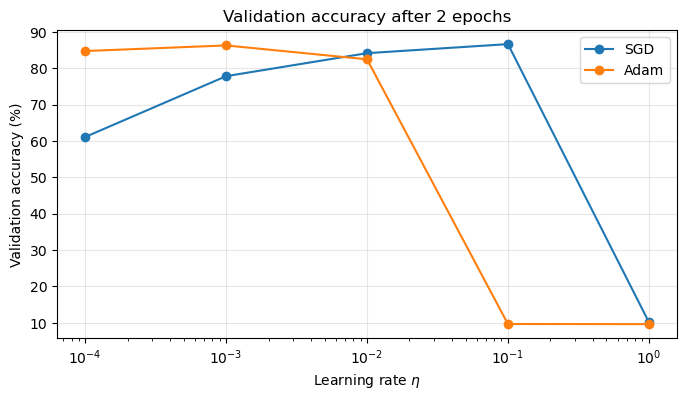

In [13]:
plt.figure(figsize=(8, 4))
for name, accs in sensitivity.items():
    plt.semilogx(learning_rates, np.array(accs) * 100, 'o-', label=name)
plt.xlabel(r"Learning rate $\eta$")
plt.ylabel("Validation accuracy (%)")
plt.title("Validation accuracy after 2 epochs")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

Both optimizers have a range of "good" learning rates, and both of them diverge when the learning rate is too large. However, the ranges are very different: Adam works well for learning rates between $10^{-4}$ and $10^{-2}$, i.e. around its default value $\eta = 10^{-3}$, while SGD requires learning rates which are $10$ to $100$ times larger, and it is very slow for small learning rates. Since the right learning rate of SGD depends on the scale of the gradients (i.e. on the curvature of the loss, which changes from problem to problem), it must be tuned for every new problem. On the contrary, the default learning rate of Adam is a reliable starting point for almost any problem, which is the main reason of its popularity.

### Evaluation on the test set

Finally, we evaluate the model trained with Adam on the **test set**, which we never used so far.

In [14]:
params = trained_params["Adam"]
Y_hat_test, _ = forward(params, X_test)
y_pred = Y_hat_test.argmax(axis=1)

print(f"Test loss: {cross_entropy(Y_hat_test, Y_test):.4f}")
print(f"Test accuracy: {np.mean(y_pred == y_test) * 100:.2f}%")

Test loss: 0.3800
Test accuracy: 87.23%


The test accuracy is close to the validation accuracy (about $1\%$ lower), confirming that the validation set gives a reliable estimate of the generalization ability of the model.

To better understand which errors the model makes, we compute the **confusion matrix** $C \in \mathbb{R}^{K \times K}$, where $C_{ij}$ is the number of test images of class $i$ which have been classified as class $j$. A perfect classifier would have a diagonal confusion matrix.

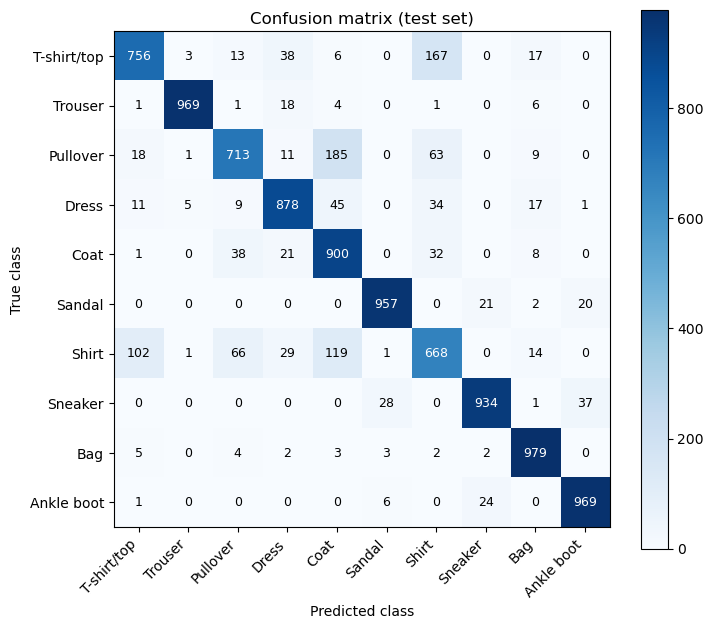

T-shirt/top : accuracy = 75.6%
Trouser     : accuracy = 96.9%
Pullover    : accuracy = 71.3%
Dress       : accuracy = 87.8%
Coat        : accuracy = 90.0%
Sandal      : accuracy = 95.7%
Shirt       : accuracy = 66.8%
Sneaker     : accuracy = 93.4%
Bag         : accuracy = 97.9%
Ankle boot  : accuracy = 96.9%


In [15]:
C = np.zeros((K, K), dtype=int)
for true, pred in zip(y_test, y_pred):
    C[true, pred] += 1

plt.figure(figsize=(8, 7))
plt.imshow(C, cmap="Blues")
for i in range(K):
    for j in range(K):
        plt.text(j, i, C[i, j], ha="center", va="center",
                 color="white" if C[i, j] > C.max() / 2 else "black", fontsize=9)
plt.xticks(range(K), CLASSES, rotation=45, ha="right")
plt.yticks(range(K), CLASSES)
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title("Confusion matrix (test set)")
plt.colorbar()
plt.show()

for k in range(K):
    print(f"{CLASSES[k]:12s}: accuracy = {C[k, k] / C[k].sum() * 100:.1f}%")

As expected, the hardest classes are the ones that look similar to each other: *Shirt*, *T-shirt/top*, *Pullover* and *Coat* are often confused, while *Trouser*, *Bag* and the shoes are classified almost perfectly. Let's look at some of the misclassified images, together with the probability that the network assigned to its prediction.

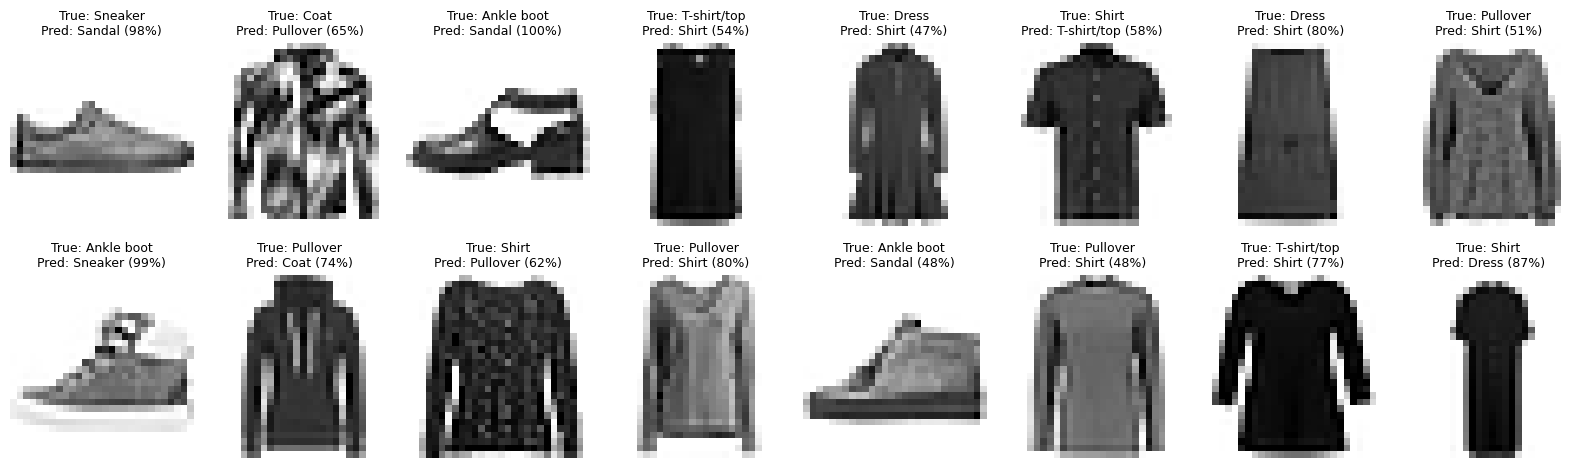

In [16]:
wrong = np.where(y_pred != y_test)[0]

fig, axes = plt.subplots(2, 8, figsize=(16, 5))
for ax, i in zip(axes.ravel(), wrong[:16]):
    ax.imshow(X_test[i].reshape(28, 28), cmap="gray_r")
    ax.set_title(f"True: {CLASSES[y_test[i]]}\nPred: {CLASSES[y_pred[i]]} ({Y_hat_test[i].max()*100:.0f}%)",
                 fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

Many of these errors are understandable, even for a human.

## Conclusions

In this course, we built from scratch, using only `numpy`, all the components of a modern Deep Learning pipeline:

- a **model**: the Multi-Layer Perceptron, built as a graph of simple computational units (the neurons);
- a **loss function**: the Cross-Entropy, derived from the Maximum Likelihood principle;
- the **gradient** of the loss, computed efficiently by **backpropagation**;
- the **optimizers**: Gradient Descent, Stochastic Gradient Descent, Momentum and Adam;
- the **data pipeline**: download, loading, pre-processing, train/validation/test split, evaluation.

Libraries such as PyTorch implement exactly these components (with automatic differentiation in place of our hand-written `backward`, and GPUs in place of our CPU), allowing to scale them to models with billions of parameters. However, the mathematical principles behind them are exactly the ones we studied in this course.

> **Exercise (Normalization):** Train the MLP with SGD and Adam **without** standardizing the data (i.e. with pixel values in $\{0, \dots, 255\}$). What happens? Which optimizer is more robust? Explain the result using what you learned about the conditioning of the problem and about the scale-invariance of Adam.

> **Exercise (Batch size):** Train the MLP with Adam for $N_\text{batch} \in \{16, 64, 256, 1024\}$, keeping the number of epochs fixed. Plot the validation accuracy as a function of the epochs and as a function of the training time.

> **Exercise (Architecture):** Try different architectures: a single hidden layer with $32$, $128$ or $512$ neurons, and three hidden layers with $256$ neurons each. How do the number of parameters, the training time and the test accuracy change? Do you observe more overfitting with larger networks?

> **Exercise (Early stopping):** Modify the function `train` so that it keeps a copy of the parameters corresponding to the lowest validation loss, and returns them at the end of the training. Compare the test accuracy of these parameters with the ones obtained at the last epoch.

> **Exercise (MNIST):** Repeat the experiment on the original MNIST dataset of handwritten digits, which can be downloaded in the same format from [https://storage.googleapis.com/cvdf-datasets/mnist/](https://storage.googleapis.com/cvdf-datasets/mnist/) (with the same file names). Which accuracy do you obtain?